# GLD965 15m: nested waterfall, tuned direction models

Forecast next contiguous 15-minute volatility-scaled return. Z_return_lag5 is a historical predictor, subject to the same waterfall. Four outer time-series folds, thirty-bar embargo, separate inner selection and tuning blocks. Source code records all thresholds and search grids.

In [1]:
import sys
from pathlib import Path
repo=Path('/workspace/tidewatch_wiki') if Path('/workspace/tidewatch_wiki').exists() else next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'research/mts_gold').exists())
sys.path.insert(0,str(repo/'research/mts_gold/code'))
from model1_15m_waterfall import run,CONFIG,GRIDS
from IPython.display import display,Image
display(CONFIG)
display(GRIDS)
results=run()

{'target': 'next contiguous 15m log return / EWMA sigma(t), clipped [-5,5]',
 'Z_return_lag5': 'one-bar log return five observed MTS bars ago / sigma at that historical bar; clipped [-5,5]',
 'outer_folds': 4,
 'embargo_context_bars': 30,
 'ewma_half_life': 30,
 'null_threshold': 0.2,
 'vif_threshold': 10,
 'varclus_top_per_cluster': 3,
 'permutation_top_max': 45,
 'seed': 42,
 'selection': 'inner training diagnostics; separate chronological selection and tuning blocks inside outer training',
 'source_lags': 'existing source lag fields shifted one additional MTS row: all X ends strictly before decision bar',
 'near_zero_band': 0.05}

{'Lasso': {'alpha': [0.001, 0.01, 0.1]},
 'ElasticNet': {'alpha': [0.001, 0.01, 0.1], 'l1_ratio': [0.25, 0.75]},
 'LightGBMRegressor': {'n_estimators': [100, 250],
  'learning_rate': [0.03, 0.07],
  'min_child_samples': [50, 150]}}

Fold 1 start


Fold 1 complete, selected 45


Fold 2 start


Fold 2 complete, selected 45


Fold 3 start


Fold 3 complete, selected 45


Fold 4 start


Fold 4 complete, selected 45


            model  rows    mse_z    mae_z  zero_baseline_mse  r2_vs_zero  mse_improvement_vs_zero  directional_rows  directional_coverage  directional_accuracy  mse_improvement_ci_low  mse_improvement_ci_high  r2_ci_low  r2_ci_high acceptance_ci_positive                                          bootstrap_method
       ElasticNet 33820 1.017330 0.737434           1.017069   -0.000257                -0.000261                23              0.000680              0.434783               -0.000686                 0.000199  -0.000674    0.000198                  False paired circular 30-observation blocks, stratified by fold
            Lasso 33820 1.017298 0.737426           1.017069   -0.000225                -0.000229                19              0.000562              0.526316               -0.000644                 0.000222  -0.000631    0.000214                  False paired circular 30-observation blocks, stratified by fold
LightGBMRegressor 33820 1.017836 0.737364           1.017069 

In [2]:
display(results['waterfall'])
display(results['schedule'])
display(results['selected_features'])
display(results['summary'])
display(results['pairwise_comparison'])

,fold,stage,before,after,dropped,dropped_features
0,1,1 strictly lagged inputs,246,196,50,open;high;low;close;source_count;purity_pct;mt...
1,1,2 null >=20%,196,129,67,mts_xauusd_1d_close_lag30;mts_xauusd_1d_return...
2,1,3 zero variance,129,123,6,mts_xauusd_1d_elapsed_min_lag5;btcusdt_15m_ela...
3,1,4 VARCLUS top 3 per cluster,123,79,44,mts965_15m_close_lag1;mts965_15m_close_lag5;mt...
4,1,5 iterative VIF >10,79,48,31,mts_xauusd_15m_close_lag5;mts_xauusd_15m_close...
5,1,6 Lasso permutation top up to 45,48,45,3,btcusdt_15m_return_lag1;own_return_skew15_lag1...
6,2,1 strictly lagged inputs,246,196,50,open;high;low;close;source_count;purity_pct;mt...
7,2,2 null >=20%,196,133,63,mts_xauusd_1d_close_lag30;mts_xauusd_1d_return...
8,2,3 zero variance,133,127,6,btcusdt_15m_elapsed_min_lag1;btcusdt_15m_elaps...
9,2,4 VARCLUS top 3 per cluster,127,77,50,mts965_15m_elapsed_min_lag1;mts965_15m_close_l...


,fold,train_rows,selection_fit_rows,permutation_rows,tuning_rows,test_rows,train_end,test_start,test_end,inner_seed,outer_seed,features
0,1,8423,5055,1656,1654,8454,2025-05-16 01:15:00+00:00,2025-05-16 09:15:00+00:00,2025-09-30 06:30:00+00:00,5.439926e-07,9.965126e-07,45
1,2,16878,10123,3349,3344,8451,2025-09-29 23:00:00+00:00,2025-09-30 07:00:00+00:00,2026-02-12 05:15:00+00:00,9.422596e-07,7.361457e-07,45
2,3,25331,15199,5037,5034,8458,2026-02-11 20:30:00+00:00,2026-02-12 05:45:00+00:00,2026-06-26 13:15:00+00:00,7.619887e-07,1.477534e-06,45
3,4,33789,20270,6728,6729,8457,2026-06-26 05:45:00+00:00,2026-06-26 13:45:00+00:00,2026-11-06 21:45:00+00:00,9.518756e-07,1.763778e-06,45


,fold,feature
0,1,own_return_min7_lag1
1,1,own_return_variance15_lag1
2,1,btcusdt_15m_volume_lag1
3,1,mts9999_15m_return_lag30
4,1,btcusdt_15m_return_lag5
...,...,...
175,4,us_yield_10y_1d_close_lag5
176,4,us_yield_2y_1d_close_lag30
177,4,us_yield_2y_1d_return_lag1
178,4,us_yield_2y_1d_return_lag30


,model,rows,mse_z,mae_z,zero_baseline_mse,r2_vs_zero,mse_improvement_vs_zero,directional_rows,directional_coverage,directional_accuracy,mse_improvement_ci_low,mse_improvement_ci_high,r2_ci_low,r2_ci_high,acceptance_ci_positive,bootstrap_method
0,ElasticNet,33820,1.017330,0.737434,1.017069,-0.000257,-0.000261,23,0.000680,0.434783,-0.000686,0.000199,-0.000674,0.000198,False,"paired circular 30-observation blocks, stratif..."
1,Lasso,33820,1.017298,0.737426,1.017069,-0.000225,-0.000229,19,0.000562,0.526316,-0.000644,0.000222,-0.000631,0.000214,False,"paired circular 30-observation blocks, stratif..."
2,LightGBMRegressor,33820,1.017836,0.737364,1.017069,-0.000754,-0.000767,9620,0.284447,0.519854,-0.001745,0.000180,-0.001708,0.000182,False,"paired circular 30-observation blocks, stratif..."
3,zero,33820,1.017069,0.737546,1.017069,0.000000,0.000000,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,first,second,mean_mse_advantage_first,mse_improvement_ci_low,mse_improvement_ci_high,r2_ci_low,r2_ci_high,acceptance_ci_positive,bootstrap_method
0,Lasso,ElasticNet,0.000033,-0.000030,0.000095,-0.000030,0.000093,False,"paired circular 30-observation blocks, stratif..."
1,Lasso,LightGBMRegressor,0.000539,-0.000325,0.001407,-0.000322,0.001372,False,"paired circular 30-observation blocks, stratif..."
2,ElasticNet,LightGBMRegressor,0.000506,-0.000346,0.001364,-0.000344,0.001341,False,"paired circular 30-observation blocks, stratif..."


,fold,model,parameters,rows,mse_z,mae_z,zero_baseline_mse,r2_vs_zero,mse_improvement_vs_zero,directional_rows,directional_coverage,directional_accuracy
0,1,zero,{},8454,1.022791,0.755289,1.022791,0.000000,0.000000,0,0.000000,NaN
1,1,Lasso,"{""alpha"": 0.1}",8454,1.022345,0.755086,1.022791,0.000436,0.000446,0,0.000000,NaN
2,1,ElasticNet,"{""alpha"": 0.1, ""l1_ratio"": 0.75}",8454,1.022345,0.755086,1.022791,0.000436,0.000446,0,0.000000,NaN
3,1,LightGBMRegressor,"{""learning_rate"": 0.03, ""min_child_samples"": 1...",8454,1.023016,0.755276,1.022791,-0.000220,-0.000225,1897,0.224391,0.524512
4,2,zero,{},8451,1.018689,0.726950,1.018689,0.000000,0.000000,0,0.000000,NaN
5,2,Lasso,"{""alpha"": 0.1}",8451,1.018295,0.726042,1.018689,0.000387,0.000394,0,0.000000,NaN
6,2,ElasticNet,"{""alpha"": 0.1, ""l1_ratio"": 0.25}",8451,1.018295,0.726042,1.018689,0.000387,0.000394,0,0.000000,NaN
7,2,LightGBMRegressor,"{""learning_rate"": 0.03, ""min_child_samples"": 1...",8451,1.018536,0.725445,1.018689,0.000150,0.000153,3963,0.468939,0.532930
8,3,zero,{},8458,1.025261,0.735744,1.025261,0.000000,0.000000,0,0.000000,NaN
9,3,Lasso,"{""alpha"": 0.1}",8458,1.026900,0.736242,1.025261,-0.001599,-0.001640,0,0.000000,NaN


,fold,model,parameters,tuning_mse
0,1,Lasso,"{""alpha"": 0.001}",1.094016
1,1,Lasso,"{""alpha"": 0.01}",1.041438
2,1,Lasso,"{""alpha"": 0.1}",1.038133
3,1,ElasticNet,"{""alpha"": 0.001, ""l1_ratio"": 0.25}",1.131530
4,1,ElasticNet,"{""alpha"": 0.001, ""l1_ratio"": 0.75}",1.105146
...,...,...,...,...
63,4,LightGBMRegressor,"{""learning_rate"": 0.03, ""min_child_samples"": 1...",1.032295
64,4,LightGBMRegressor,"{""learning_rate"": 0.07, ""min_child_samples"": 5...",1.031044
65,4,LightGBMRegressor,"{""learning_rate"": 0.07, ""min_child_samples"": 5...",1.047037
66,4,LightGBMRegressor,"{""learning_rate"": 0.07, ""min_child_samples"": 1...",1.032419


,feature,validation_rows,importance_mean,importance_std,importance_p05,importance_p95,positive_repeat_fraction,coefficient_zero,importance_definition,selected,fold
0,own_return_min7_lag1,1656,0.001702,0.001404,-0.000319,0.003445,0.85,False,increase_in_validation_MSE_z,True,1
1,own_return_variance15_lag1,1656,0.001478,0.001012,0.000342,0.003153,0.95,False,increase_in_validation_MSE_z,True,1
2,btcusdt_15m_volume_lag1,1656,0.000643,0.000771,-0.000399,0.002143,0.85,False,increase_in_validation_MSE_z,True,1
3,mts9999_15m_return_lag30,1656,0.000559,0.000492,-0.000157,0.001142,0.85,False,increase_in_validation_MSE_z,True,1
4,btcusdt_15m_return_lag5,1656,0.000551,0.000774,-0.000493,0.001874,0.65,False,increase_in_validation_MSE_z,True,1
...,...,...,...,...,...,...,...,...,...,...,...
220,own_return_min15_lag1,6728,-0.000019,0.000175,-0.000293,0.000155,0.55,False,increase_in_validation_MSE_z,False,4
221,us_yield_2y_1d_elapsed_min_lag30,6728,-0.000025,0.000021,-0.000064,0.000007,0.15,False,increase_in_validation_MSE_z,False,4
222,own_return_kurtosis7_lag1,6728,-0.000085,0.000058,-0.000161,0.000041,0.10,False,increase_in_validation_MSE_z,False,4
223,us_yield_3m_1d_return_lag30,6728,-0.000102,0.000201,-0.000385,0.000186,0.30,False,increase_in_validation_MSE_z,False,4


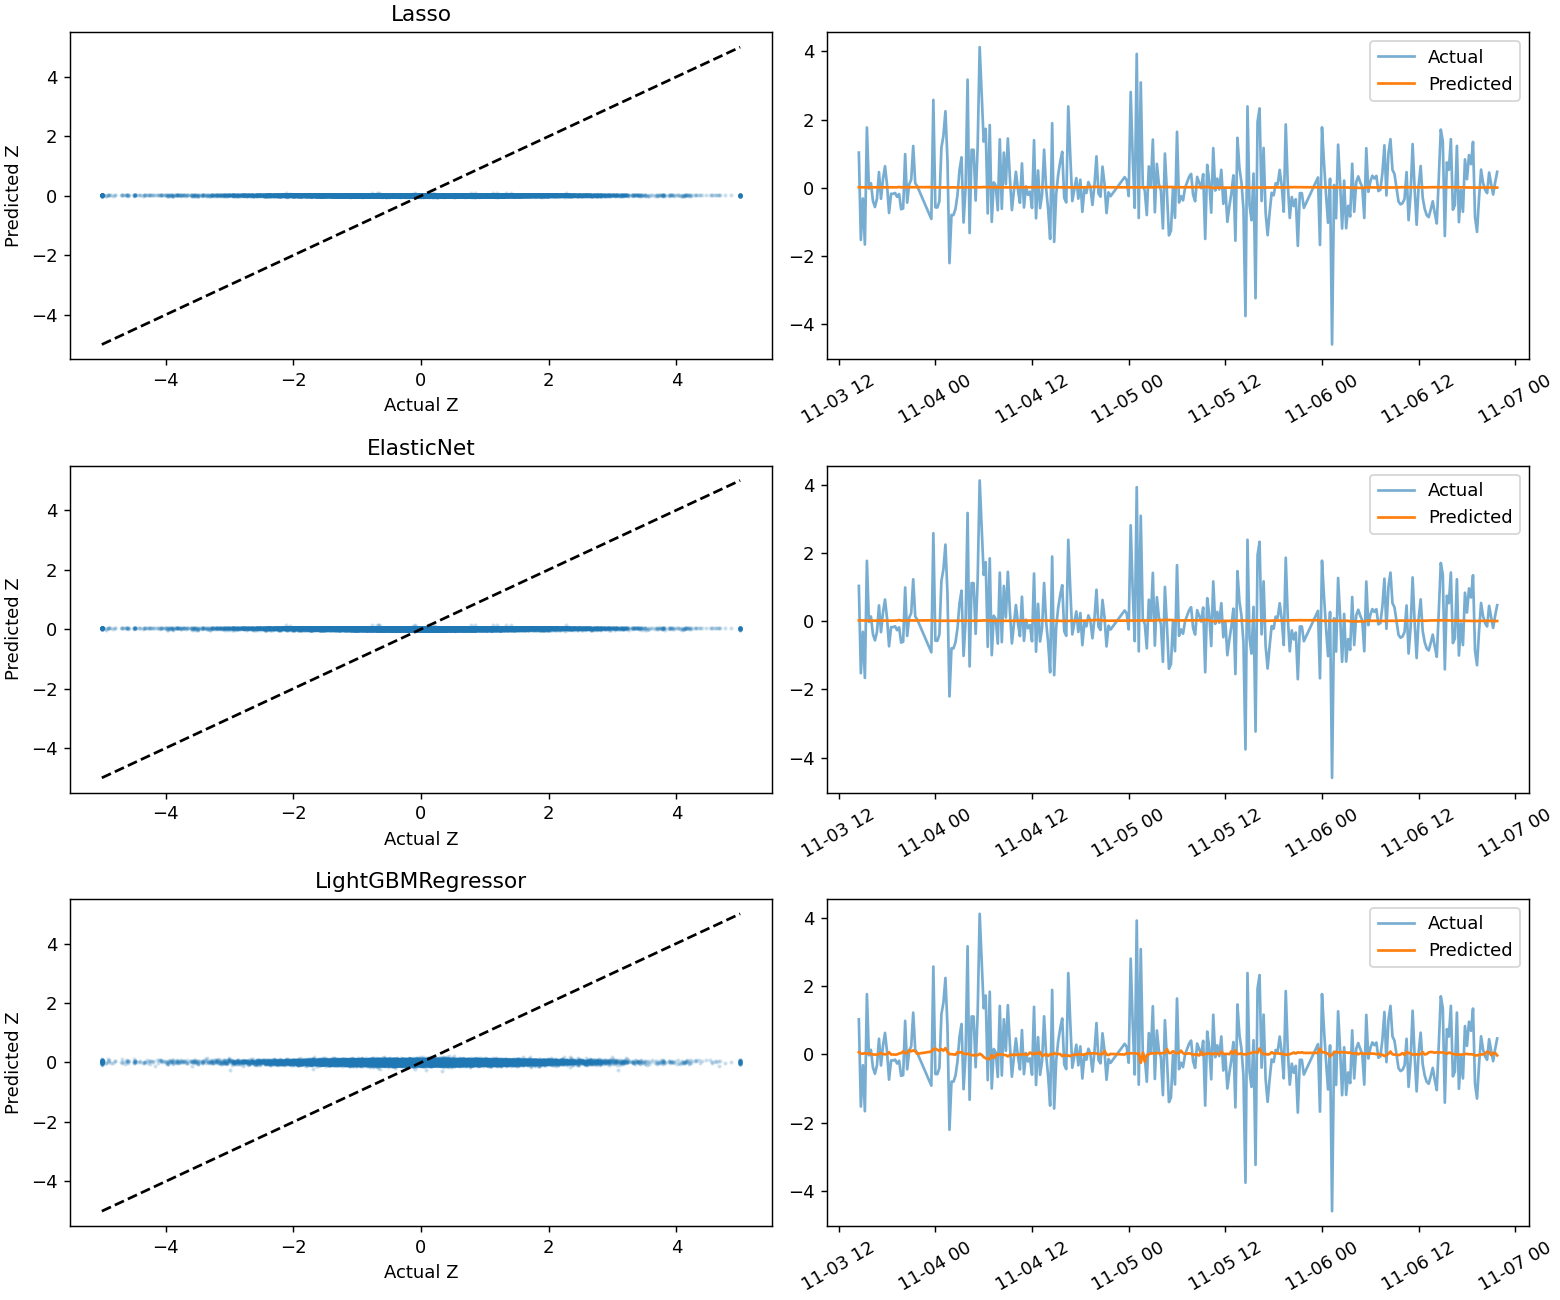

,decision_at,label_at,close,next_return,sigma,y_z,z_hat,model,fold
0,2025-05-16 09:15:00+00:00,2025-05-16 09:30:00+00:00,50383.0,0.000992,0.001192,0.832123,0.0,zero,1
1,2025-05-16 09:30:00+00:00,2025-05-16 09:45:00+00:00,50433.0,-0.000813,0.001188,-0.684689,0.0,zero,1
2,2025-05-16 09:45:00+00:00,2025-05-16 10:00:00+00:00,50392.0,0.000595,0.001181,0.504114,0.0,zero,1
3,2025-05-16 10:00:00+00:00,2025-05-16 10:15:00+00:00,50422.0,-0.001211,0.001170,-1.034194,0.0,zero,1
4,2025-05-16 10:15:00+00:00,2025-05-16 10:30:00+00:00,50361.0,-0.000119,0.001171,-0.101711,0.0,zero,1
5,2025-05-16 10:30:00+00:00,2025-05-16 10:45:00+00:00,50355.0,-0.001749,0.001158,-1.510321,0.0,zero,1
6,2025-05-16 10:45:00+00:00,2025-05-16 11:00:00+00:00,50267.0,-0.004027,0.001175,-3.427121,0.0,zero,1
7,2025-05-16 11:00:00+00:00,2025-05-16 11:15:00+00:00,50065.0,-0.001539,0.001311,-1.173869,0.0,zero,1
8,2025-05-16 11:15:00+00:00,2025-05-16 11:30:00+00:00,49988.0,0.000140,0.001317,0.106332,0.0,zero,1
9,2025-05-16 11:30:00+00:00,2025-05-16 11:45:00+00:00,49995.0,0.000400,0.001302,0.307213,0.0,zero,1


In [3]:
display(results['fold_metrics'])
display(results['tuning'])
display(results['permutation'])
display(Image(filename=str(repo/'research/mts_gold/training_artifacts/_training_baseline/model1_15m_waterfall/predicted_actual.png')))
display(results['predictions'].head(20))